# Market & Business Case

Market-sizing figures for the QORC pitch deck. All numbers are drawn from public
2024–2025 market-research estimates; where firms disagree we use a mid-range value
and keep the source range in the notes.

| Metric | Value used | Source range |
|---|---|---|
| Global cybersecurity market 2024 | **$229B** | $227–239B |
| Global cybersecurity market 2029 | **$397B** | $352–397B |
| Cybersecurity CAGR | **~11.6%** | 9–12% |
| AI-in-cybersecurity 2024 | **$25B** | $19–31B |
| AI-in-cybersecurity 2030 | **$94B** | $64–135B |
| AI-cyber CAGR | **~24%** | 22–28% |
| Avg. cost of an AI-powered breach | **$5.7M** | — |

> Sources: MarketsandMarkets, Grand View Research, Strategic Market Research, IBM Cost of a Data Breach.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.22, 'grid.linewidth': 0.6,
})

# deck palette
C_CYBER = '#2AA9D6'   # photon cyan  -> total market
C_AI    = '#E8890C'   # phase amber  -> AI segment (our arena)
C_ACC   = '#6D4AE0'   # readout violet
C_WARN  = '#C0392B'
usd = FuncFormatter(lambda v, _: f'${v:,.0f}B')

## 1. Market growth — total cybersecurity vs the AI segment we play in

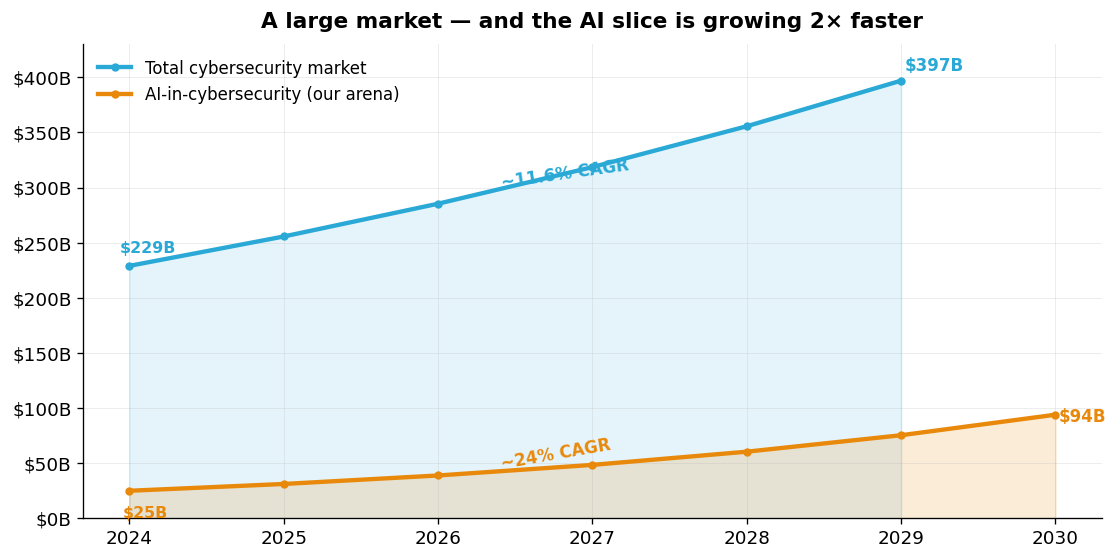

In [2]:
# smooth CAGR curves between anchor points
def cagr_curve(v0, v1, y0, y1):
    yrs = np.arange(y0, y1 + 1)
    r = (v1 / v0) ** (1 / (y1 - y0))
    return yrs, v0 * r ** (yrs - y0)

yc, cyber = cagr_curve(229, 397, 2024, 2029)     # total cybersecurity
ya, ai    = cagr_curve(25, 94, 2024, 2030)       # AI-in-cybersecurity

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.fill_between(yc, cyber, color=C_CYBER, alpha=0.12)
ax.plot(yc, cyber, color=C_CYBER, lw=2.6, marker='o', ms=4, label='Total cybersecurity market')
ax.fill_between(ya, ai, color=C_AI, alpha=0.16)
ax.plot(ya, ai, color=C_AI, lw=2.6, marker='o', ms=4, label='AI-in-cybersecurity (our arena)')

# endpoint labels
ax.annotate('$229B', (2024, 229), textcoords='offset points', xytext=(-6,8), fontsize=9.5, color=C_CYBER, fontweight='bold')
ax.annotate('$397B', (2029, 397), textcoords='offset points', xytext=(2,6),  fontsize=10, color=C_CYBER, fontweight='bold')
ax.annotate('$25B',  (2024, 25),  textcoords='offset points', xytext=(-4,-16), fontsize=9.5, color=C_AI, fontweight='bold')
ax.annotate('$94B',  (2030, 94),  textcoords='offset points', xytext=(2,-4),  fontsize=10, color=C_AI, fontweight='bold')

ax.text(2026.4, 300, '~11.6% CAGR', color=C_CYBER, fontsize=10, rotation=8, fontweight='bold')
ax.text(2026.4, 45,  '~24% CAGR',  color=C_AI, fontsize=10, rotation=10, fontweight='bold')

ax.set_ylim(0, 430); ax.yaxis.set_major_formatter(usd)
ax.set_xticks(range(2024, 2031))
ax.set_title('A large market — and the AI slice is growing 2× faster',
             fontsize=13, fontweight='bold', pad=10)
ax.legend(frameon=False, loc='upper left', fontsize=10)
plt.tight_layout()
plt.savefig('fig_market_growth.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Why now — the cost of missing a zero-day

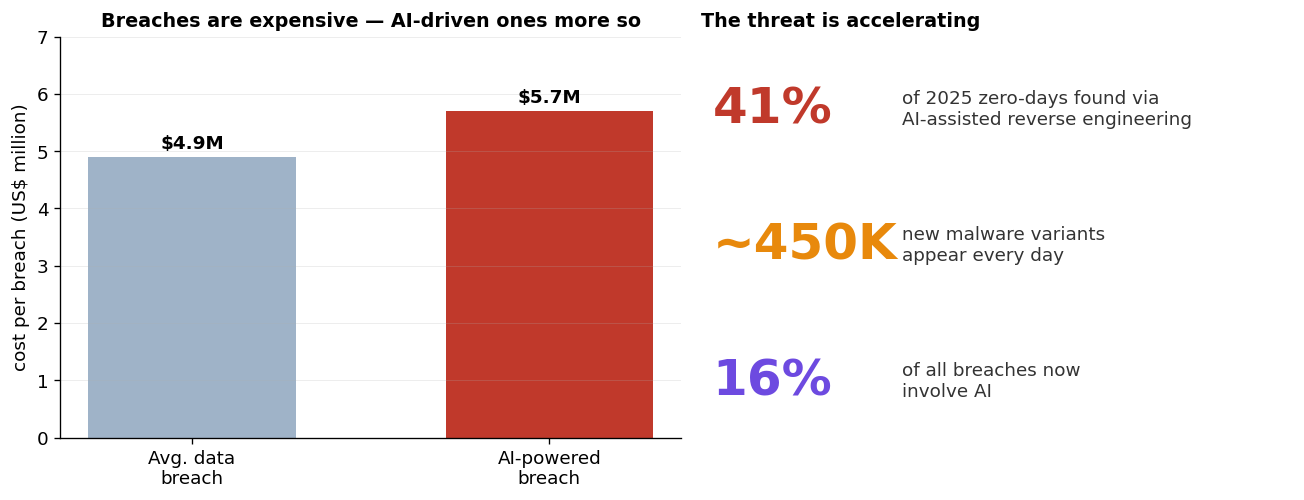

In [3]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw={'width_ratios':[1.05,1]})

# (L) breach cost comparison
labels = ['Avg. data\nbreach', 'AI-powered\nbreach']
vals   = [4.9, 5.7]   # $M ; IBM avg ~4.9M, AI-powered ~5.7M
bars = axL.bar(labels, vals, color=['#9FB3C8', C_WARN], width=0.58)
axL.set_ylabel('cost per breach (US$ million)')
axL.set_ylim(0, 7)
for b, v in zip(bars, vals):
    axL.text(b.get_x()+b.get_width()/2, v+0.15, f'${v:.1f}M', ha='center', fontweight='bold', fontsize=11)
axL.set_title('Breaches are expensive — AI-driven ones more so', fontsize=11.5, fontweight='bold')
axL.grid(axis='x', alpha=0)

# (R) headline stats as big numbers
axR.axis('off')
stats = [
    ('41%',   'of 2025 zero-days found via\nAI-assisted reverse engineering', C_WARN),
    ('~450K', 'new malware variants\nappear every day', C_AI),
    ('16%',   'of all breaches now\ninvolve AI', C_ACC),
]
for i, (big, small, col) in enumerate(stats):
    y = 0.82 - i*0.34
    axR.text(0.02, y, big, fontsize=30, fontweight='bold', color=col, transform=axR.transAxes, va='center')
    axR.text(0.34, y, small, fontsize=11, color='#333', transform=axR.transAxes, va='center')
axR.set_title('The threat is accelerating', fontsize=11.5, fontweight='bold', loc='left')

plt.tight_layout()
plt.savefig('fig_why_now.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Where the money is — buyer segments & the wedge

The buyers who feel zero-day pain most: finance, critical infrastructure, telecom,
government/defense, cloud. This is the beachhead — not the whole market, the wedge.

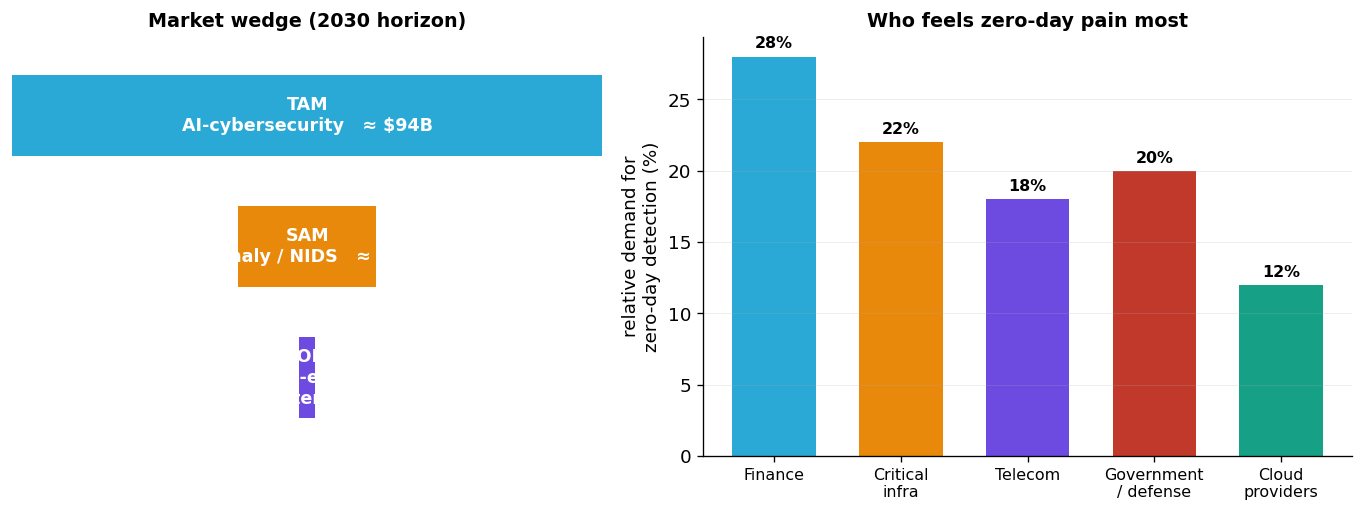

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={'width_ratios':[1,1.1]})

# (L) TAM / SAM / SOM funnel
tiers = ['TAM\nAI-cybersecurity', 'SAM\nanomaly / NIDS', 'SOM\nquantum-enhanced\nearly adopters']
vals  = [94, 22, 2.5]   # $B, illustrative SAM/SOM
cols  = [C_CYBER, C_AI, C_ACC]
widths = [v/vals[0] for v in vals]
for i,(t,w,c,v) in enumerate(zip(tiers, widths, cols, vals)):
    left = (1-w)/2
    ax1.barh(2-i, w, left=left, color=c, height=0.62)
    ax1.text(0.5, 2-i, f'{t}   ≈ ${v:g}B', ha='center', va='center', color='white',
             fontsize=10.5, fontweight='bold')
ax1.set_xlim(0,1); ax1.set_ylim(-0.6,2.6); ax1.axis('off')
ax1.set_title('Market wedge (2030 horizon)', fontsize=11.5, fontweight='bold')

# (R) buyer segments
seg = ['Finance', 'Critical\ninfra', 'Telecom', 'Government\n/ defense', 'Cloud\nproviders']
share = [28, 22, 18, 20, 12]
b = ax2.bar(range(len(seg)), share, color=[C_CYBER,C_AI,C_ACC,'#C0392B','#16A085'], width=0.66)
ax2.set_xticks(range(len(seg))); ax2.set_xticklabels(seg, fontsize=9.5)
ax2.set_ylabel('relative demand for\nzero-day detection (%)')
for bb,v in zip(b,share):
    ax2.text(bb.get_x()+bb.get_width()/2, v+0.6, f'{v}%', ha='center', fontsize=9.5, fontweight='bold')
ax2.set_title('Who feels zero-day pain most', fontsize=11.5, fontweight='bold')
ax2.grid(axis='x', alpha=0)

plt.tight_layout()
plt.savefig('fig_tam_segments.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
print('BUSINESS CASE  —  one-line takeaways')
print('='*50)
print('  $229B → $397B  total cybersecurity market (2024→2029, ~11.6% CAGR)')
print('  $25B  → $94B   AI-in-cybersecurity  (2024→2030, ~24% CAGR — 2× faster)')
print('  $5.7M          average cost of an AI-powered breach')
print('  ~450K/day      new malware variants — signatures always lag')
print('  Wedge          quantum-enhanced anomaly detection for high-pain buyers')
print()
print('  NOTE: figures are mid-range public estimates; verify against a current')
print('        market report before the final pitch.')

BUSINESS CASE  —  one-line takeaways
  $229B → $397B  total cybersecurity market (2024→2029, ~11.6% CAGR)
  $25B  → $94B   AI-in-cybersecurity  (2024→2030, ~24% CAGR — 2× faster)
  $5.7M          average cost of an AI-powered breach
  ~450K/day      new malware variants — signatures always lag
  Wedge          quantum-enhanced anomaly detection for high-pain buyers

  NOTE: figures are mid-range public estimates; verify against a current
        market report before the final pitch.
